# Phyllotaxis

A sunflower adds its seeds one at a time, each turned 137.5° from the one before. That angle, the
golden angle, is the one that stays farthest from ever lining up with an earlier seed, so the
seeds pack evenly with no gaps. The spirals that run both ways come in Fibonacci numbers.

In [1]:
import math

from common import hsv
from nbturtle import render

## Placing the seeds

The turtle doesn't walk here. It jumps to each seed with `goto`, pen up, and stamps a `dot`.
Seed *n* sits at angle *n* × 137.5° and at distance √*n* from the center, which gives every seed
the same area. Dot size and color grow with *n*, so the outer, older seeds are bigger and pinker.

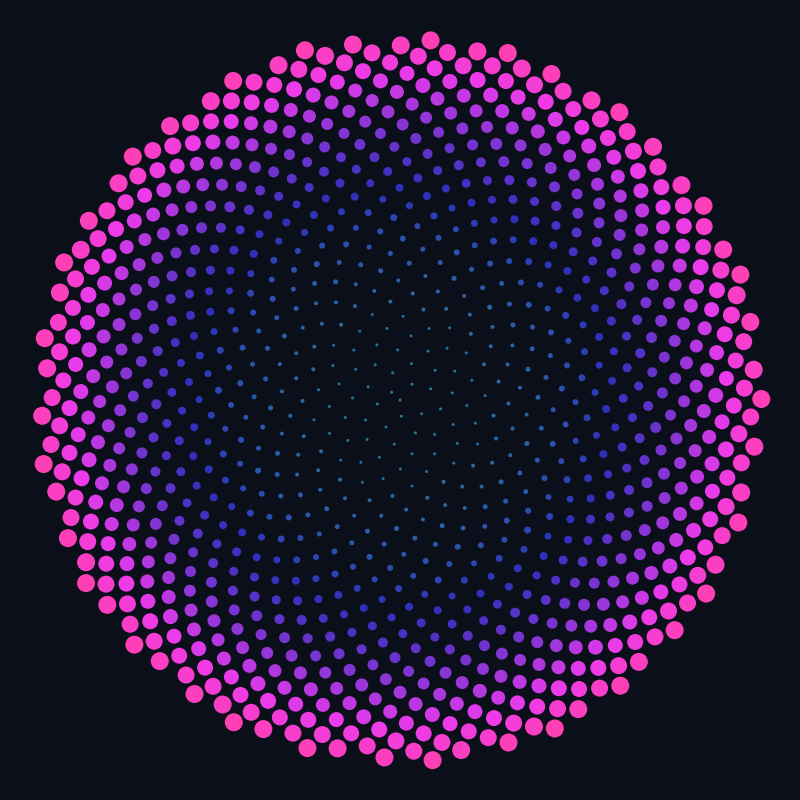

In [2]:
GOLDEN_ANGLE = math.radians(137.50776)
COUNT = 1000
SCALE = 11.5


def draw(t):
    for n in range(COUNT):
        angle = n * GOLDEN_ANGLE
        radius = SCALE * math.sqrt(n)
        t.goto(radius * math.cos(angle), radius * math.sin(angle))
        f = n / COUNT
        t.dot(int(3 + 16 * f), hsv(0.55 + 0.35 * f, 0.75, 0.6 + 0.4 * f))


render(draw)

## Why that angle?

The same 500 seeds at three angles. At 135°, three eighths of a turn, every eighth seed lands on
the same ray and the head splits into 8 spokes. The golden angle fills the disc evenly. Half a
degree past it, at 138°, the seeds line up into curved arms with gaps between them.

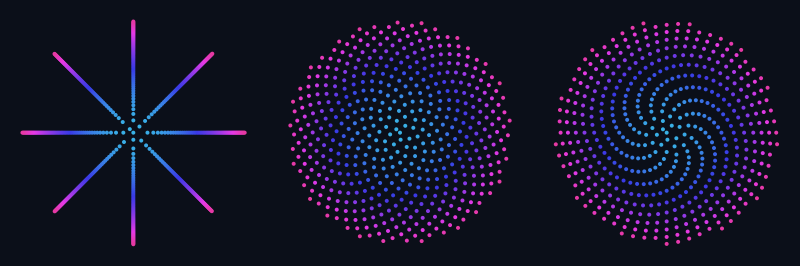

In [3]:
def sunflower(t, degrees, cx, count=500, scale=7.5):
    for n in range(count):
        angle = math.radians(n * degrees)
        radius = scale * math.sqrt(n)
        t.goto(cx + radius * math.cos(angle), radius * math.sin(angle))
        t.dot(6, hsv(0.55 + 0.35 * n / count, 0.75, 0.9))


def compare(t):
    for k, degrees in enumerate((135, 137.50776, 138)):
        sunflower(t, degrees, (k - 1) * 400)


render(compare, 1200, 400, dpi=48)

## Try

- `GOLDEN_ANGLE = math.radians(137.3)`: a fraction of a degree off and the spirals change.
- A constant dot size, `t.dot(8, …)`, shows how evenly the seeds are spread.
- `COUNT = 3000` with `SCALE = 6.5` for a bigger head.